# Environment check and a first diffusion model on your machine

Booster LEAP, Diffusion Models, topic 1. You check your Python environment and GPU, do the memory arithmetic of lesson 4 on real numbers, and train and sample a tiny diffusion model on your own machine or on a Colab GPU.

<h1 style="color:#b45309">&#9888; First: File &rarr; Save a copy in Drive</h1>

<span style="font-size:20px">This notebook is read-only. Make your own copy now, then work in the copy (no GitHub login needed).</span>

**How to use this notebook:** run the cells from top to bottom (Runtime, Run all, or Shift+Enter on each cell). It needs no GPU. It loads three real photographs from our public GitHub repository (an internet connection is needed, Colab has one). Photos: china.jpg and flower.jpg are scikit-learn sample images (Flickr users danielbuechele and vultilion, CC BY 2.0); grace_hopper.jpg is a U.S. Navy photograph, public domain. Change one thing at a time and run again; the last cell tells you what to try, including your own photo.

**What you need to know first:** nothing about diffusion. Two ideas help: a *Gaussian* is the bell-curve random number (`np.random.standard_normal`), and a *pixel value* is a number from 0 to 255. Everything else is explained where it appears.

## 1. Check the environment

This cell imports the libraries of the course, prints their versions and finds out whether a GPU is available. On Colab, choose a GPU runtime first (Runtime, Change runtime type) and run it again to see the difference.

In [ ]:
import importlib, platform, sys, time

print("python", sys.version.split()[0], "|", platform.system(), platform.machine())
for name, pip_name in [("numpy", "numpy"), ("PIL", "pillow"), ("matplotlib", "matplotlib"), ("sklearn", "scikit-learn"), ("torch", "torch"), ("diffusers", "diffusers")]:
    try:
        mod = importlib.import_module(name)
        print("  %-11s %s" % (name, getattr(mod, "__version__", "installed")))
    except ImportError:
        print("  %-11s MISSING  ->  python -m pip install %s" % (name, pip_name))

try:
    import torch
    if torch.cuda.is_available():
        p = torch.cuda.get_device_properties(0)
        print("device: GPU %s, %.1f GiB of memory" % (p.name, p.total_memory / 2**30))
        device = "cuda"
    elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        print("device: Apple GPU (mps)")
        device = "mps"
    else:
        print("device: CPU only (%d threads). Fine for every cell of this course; pretrained image models need a GPU." % torch.get_num_threads())
        device = "cpu"
    a = torch.randn(1000, 1000, device=device)
    t0 = time.perf_counter()
    for _ in range(20):
        a @ a
    if device == "cuda":
        torch.cuda.synchronize()
    print("20 matrix products of 1000 x 1000 took %.0f ms on %s (your number will differ)" % ((time.perf_counter() - t0) * 1000, device))
except ImportError:
    print("torch is missing, so nothing can be said about the GPU yet")

python 3.13.14 | Windows AMD64
  numpy       2.5.2
  PIL         12.3.0
  matplotlib  3.11.1
  sklearn     1.9.1
  torch       2.14.0+cpu
  diffusers   0.43.0
device: CPU only (4 threads). Fine for every cell of this course; pretrained image models need a GPU.
20 matrix products of 1000 x 1000 took 277 ms on cpu (your number will differ)


## 2. Memory arithmetic

Weights take parameters times bytes per number. Training with Adam keeps the weights, their gradients and two running statistics: four numbers per parameter. Change the numbers and run again.

In [ ]:
GIB = 2 ** 30
def weights_gib(params, bytes_per_number):
    return params * bytes_per_number / GIB

def training_gib(params, bytes_per_number):
    return 4 * params * bytes_per_number / GIB          # weights + gradients + 2 Adam statistics

def batch_mib(batch, channels, height, width, bytes_per_number=4):
    return batch * channels * height * width * bytes_per_number / 2 ** 20

# Change these numbers and run again. Then change the GPU memory to the one you have (Colab: look at the device line above).
params, gpu_gib = 1_000_000_000, 16
print("weights, float32: %.2f GiB   float16: %.2f GiB" % (weights_gib(params, 4), weights_gib(params, 2)))
print("training with Adam, float32: %.2f GiB" % training_gib(params, 4))
print("a batch of 8 pictures of 512 x 512 x 3: %.1f MiB" % batch_mib(8, 3, 512, 512))
print("the same batch as latents of 4 x 64 x 64: %.1f MiB" % batch_mib(8, 4, 64, 64))
print("fits into %d GiB before activations?" % gpu_gib, training_gib(params, 4) + batch_mib(8, 3, 512, 512) / 1024 < 0.8 * gpu_gib)

weights, float32: 3.73 GiB   float16: 1.86 GiB
training with Adam, float32: 14.90 GiB
a batch of 8 pictures of 512 x 512 x 3: 24.0 MiB
the same batch as latents of 4 x 64 x 64: 0.5 MiB
fits into 16 GiB before activations? False


## 3. Check the arithmetic on a real model

A small UNet from the diffusers library (random weights, nothing is downloaded). We measure the bytes of the weights, the gradients and the Adam statistics after one training step.

In [ ]:
import torch
try:
    from diffusers import UNet2DModel
except ImportError:                                     # Colab has torch but not always diffusers
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "diffusers"])
    from diffusers import UNet2DModel

model = UNet2DModel(sample_size=32, in_channels=3, out_channels=3, layers_per_block=1, block_out_channels=(32, 64),
                    down_block_types=("DownBlock2D", "AttnDownBlock2D"), up_block_types=("AttnUpBlock2D", "UpBlock2D"))
n = sum(p.numel() for p in model.parameters())
print("parameters:", n)
print("weights in float32: arithmetic %d bytes, measured %d bytes" % (n * 4, sum(p.numel() * p.element_size() for p in model.parameters())))

opt = torch.optim.Adam(model.parameters(), 1e-4)
x = torch.randn(2, 3, 32, 32)
loss = model(x, torch.tensor([10, 500])).sample.pow(2).mean()
loss.backward(); opt.step()
grads = sum(p.grad.numel() * p.grad.element_size() for p in model.parameters())
adam = sum(v.numel() * v.element_size() for s in opt.state.values() for k, v in s.items() if k in ("exp_avg", "exp_avg_sq"))
print("gradients: %d bytes = %.1f x the weights" % (grads, grads / (n * 4)))
print("Adam statistics: %d bytes = %.1f x the weights" % (adam, adam / (n * 4)))
print("training state in total: %d bytes = %.1f x the weights" % (n * 4 + grads + adam, (n * 4 + grads + adam) / (n * 4)))
model.half()
print("same weights in float16: %d bytes" % sum(p.numel() * p.element_size() for p in model.parameters()))

parameters: 702499
weights in float32: arithmetic 2809996 bytes, measured 2809996 bytes
gradients: 2809996 bytes = 1.0 x the weights
Adam statistics: 5619992 bytes = 2.0 x the weights
training state in total: 11239984 bytes = 4.0 x the weights
same weights in float16: 1404998 bytes


## 4. A photo as numbers

Load a photograph, turn it into a grey array of numbers between -1 and 1 and see how much memory it needs.

In [ ]:
import io, urllib.request
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

BASE = "https://raw.githubusercontent.com/boosterleap/booster-leap-notebooks/main/diffusion-models/images/"
FILES = {"china": "china.jpg", "flower": "flower.jpg", "hopper": "grace_hopper.jpg"}

def load_photo(name):
    """one of the three photos of the course, as a PIL image"""
    data = urllib.request.urlopen(BASE + FILES[name]).read()
    return Image.open(io.BytesIO(data)).convert("RGB")

# Your own photo (optional): remove the # signs, run the cell, choose a file.
# from google.colab import files
# photo = Image.open(next(iter(files.upload()))).convert("RGB")

NAME = "china"          # change to "flower" or "hopper"
photo = load_photo(NAME)
W, H = 192, 128         # we work on a small picture so every cell runs in a second
x0 = np.asarray(photo.resize((W, H), Image.LANCZOS), dtype=float) / 127.5 - 1.0     # pixel 0..255 -> value -1..1
print(NAME, "original size", photo.size, "-> working size", (W, H), " x0 shape (height, width, channels):", x0.shape, " values", round(x0.min(), 2), "to", round(x0.max(), 2))

def show(img, ax, title=""):
    ax.imshow(np.clip((img + 1) / 2, 0, 1)); ax.axis("off"); ax.set_title(title, fontsize=9)

g = np.asarray(photo.convert("L"), dtype=np.float32) / 127.5 - 1          # the grey photo as numbers between -1 and 1
print("photo", NAME, "grey array shape", g.shape, "->", g.nbytes, "bytes as float32 (%.2f MiB)" % (g.nbytes / 2 ** 20))
print("the same photo in colour at its original size:", np.asarray(photo).shape, "->", round(np.asarray(photo, dtype=np.float32).nbytes / 2 ** 20, 2), "MiB as float32")
for side in (64, 256, 512):
    print("a batch of 8 colour pictures of %d x %d as float32: %.1f MiB" % (side, side, 8 * 3 * side * side * 4 / 2 ** 20))

china original size (640, 427) -> working size (192, 128)  x0 shape (height, width, channels): (128, 192, 3)  values -1.0 to 1.0
photo china grey array shape (427, 640) -> 1093120 bytes as float32 (1.04 MiB)
the same photo in colour at its original size: (427, 640, 3) -> 3.13 MiB as float32
a batch of 8 colour pictures of 64 x 64 as float32: 0.4 MiB
a batch of 8 colour pictures of 256 x 256 as float32: 6.0 MiB
a batch of 8 colour pictures of 512 x 512 as float32: 24.0 MiB


## 5. Train a tiny diffusion model on your machine

The model learns to find the noise in noisy 8 x 8 patches of the photo (lesson 3). It uses the GPU if there is one. The last line tells you how long a training step took; run the notebook on a CPU and on a GPU and compare.

In [ ]:
import time, torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print("training on:", device)
torch.manual_seed(0)
rng = np.random.default_rng(0)

def patches(img, n, size=8):
    """n random size x size grey patches of a grey picture (values -1..1), each flattened to 64 numbers"""
    ys = rng.integers(0, img.shape[0] - size, n); xs = rng.integers(0, img.shape[1] - size, n)
    return np.stack([img[y:y + size, x:x + size].reshape(-1) for y, x in zip(ys, xs)])

train = torch.tensor(patches(g, 20000), dtype=torch.float32, device=device)
T = 1000
betas = torch.linspace(1e-4, 0.02, T, device=device)
ab = torch.cumprod(1 - betas, dim=0)

H = 256
net = torch.nn.Sequential(torch.nn.Linear(64 + 16, H), torch.nn.SiLU(), torch.nn.Linear(H, H), torch.nn.SiLU(), torch.nn.Linear(H, H), torch.nn.SiLU(), torch.nn.Linear(H, 64)).to(device)
freqs = (2 ** torch.arange(8, device=device)).float()
def predict_noise(x, t):
    u = (t.float() / T)[:, None] * freqs[None, :] * 3.14159
    return net(torch.cat([x, torch.sin(u), torch.cos(u)], dim=1))

STEPS = 3000
opt = torch.optim.Adam(net.parameters(), 1e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, STEPS)
t0 = time.perf_counter()
for step in range(STEPS):
    x0 = train[torch.randint(0, len(train), (256,), device=device)]
    t = torch.randint(0, T, (256,), device=device)
    noise = torch.randn_like(x0)
    xt = ab[t][:, None].sqrt() * x0 + (1 - ab[t][:, None]).sqrt() * noise
    loss = ((predict_noise(xt, t) - noise) ** 2).mean()
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    if step % 1000 == 0 or step == STEPS - 1:
        print("step %4d  error of the noise guess %.3f" % (step, loss.item()))
if device == "cuda":
    torch.cuda.synchronize()
secs = time.perf_counter() - t0
print("%d training steps took %.1f s on %s: %.1f ms per step" % (STEPS, secs, device, 1000 * secs / STEPS))

training on: cpu
step    0  error of the noise guess 0.992
step 1000  error of the noise guess 0.107
step 2000  error of the noise guess 0.087
step 2999  error of the noise guess 0.087
3000 training steps took 26.6 s on cpu: 8.9 ms per step


## 6. Generate from pure noise

Now the sampling loop: start from noise, guess the clean patch, step a little toward it, repeat 50 times. This is a toy: patches of 8 x 8 pixels from a model trained for a minute. It shows the mechanism, not the quality of real systems.

16 patches from pure noise, 50 steps: 0.05 s on cpu
neighbour correlation: real 0.941, generated 0.864


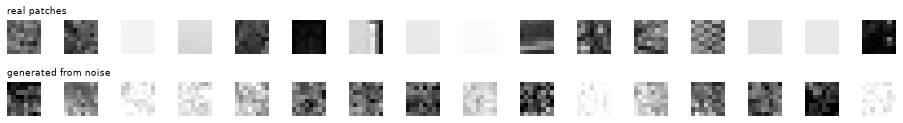

In [ ]:
@torch.no_grad()
def generate(n, steps, seed=1):
    gen = torch.Generator(device=device).manual_seed(seed)
    x = torch.randn(n, 64, generator=gen, device=device)
    ts = torch.linspace(T - 1, 0, steps, device=device).long()
    for i, t in enumerate(ts):
        a = ab[t]
        e = predict_noise(x, torch.full((n,), int(t), device=device))
        x0g = ((x - (1 - a).sqrt() * e) / a.sqrt()).clamp(-1, 1)
        e = (x - a.sqrt() * x0g) / (1 - a).sqrt()
        a_next = ab[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0, device=device)
        x = a_next.sqrt() * x0g + (1 - a_next).sqrt() * e
    return x.cpu().numpy()

t0 = time.perf_counter()
new = generate(16, 50)
print("16 patches from pure noise, 50 steps: %.2f s on %s" % (time.perf_counter() - t0, device))
real = patches(g, 16)
fig, ax = plt.subplots(2, 16, figsize=(13, 2))
for j in range(16):
    show(real[j].reshape(8, 8)[..., None].repeat(3, axis=2), ax[0, j]); show(new[j].reshape(8, 8)[..., None].repeat(3, axis=2), ax[1, j])
ax[0, 0].set_title("real patches", fontsize=9, loc="left"); ax[1, 0].set_title("generated from noise", fontsize=9, loc="left")
plt.tight_layout(); plt.show()
print("neighbour correlation: real %.3f, generated %.3f" % tuple(np.corrcoef(a.reshape(-1, 8, 8)[:, :, :-1].ravel(), a.reshape(-1, 8, 8)[:, :, 1:].ravel())[0, 1] for a in (patches(g, 2000), generate(500, 50))))

## 7. Clean a noisy photo the model never saw

The model was trained on patches of one photo. We noise a different photo and let the model clean it tile by tile.

noise step 150: noisy picture 11.7 dB, after one pass of the model 22.8 dB (trained on china, applied to flower)


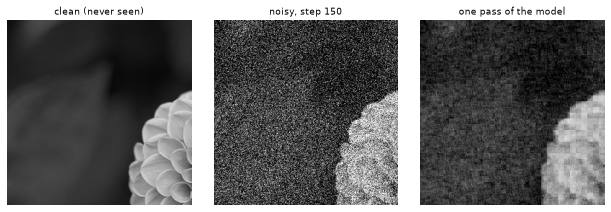

In [ ]:
# Clean a noisy picture the model never saw: another photo, noise step 150, tile by tile.
other = "flower" if NAME != "flower" else "china"
h2 = np.asarray(load_photo(other).convert("L"), dtype=np.float32)[:256, :256] / 127.5 - 1
t = 150
a = ab[t].item()
noise_pic = np.random.default_rng(3).standard_normal(h2.shape).astype(np.float32)
xt = (np.sqrt(a) * h2 + np.sqrt(1 - a) * noise_pic).astype(np.float32)
tiles = torch.tensor(xt.reshape(32, 8, 32, 8).transpose(0, 2, 1, 3).reshape(-1, 64), device=device)
with torch.no_grad():
    guess = ((tiles - np.sqrt(1 - a) * predict_noise(tiles, torch.full((len(tiles),), t, device=device))) / np.sqrt(a)).clamp(-1, 1).cpu().numpy()
den = guess.reshape(32, 32, 8, 8).transpose(0, 2, 1, 3).reshape(256, 256)
psnr = lambda p, q: 10 * np.log10(4 / np.mean((p - q) ** 2))
print("noise step %d: noisy picture %.1f dB, after one pass of the model %.1f dB (trained on %s, applied to %s)" % (t, psnr(h2, xt / np.sqrt(a)), psnr(h2, den), NAME, other))
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for axx, im, title in zip(ax, (h2, xt, den), ("clean (never seen)", "noisy, step 150", "one pass of the model")):
    show(im[..., None].repeat(3, axis=2), axx, title)
plt.tight_layout(); plt.show()

## Try it yourself

1. Run the environment check on a computer and on a Colab GPU (Runtime, Change runtime type). Compare the device line and the matrix-product time.
2. In the memory cell change `params` to 7_000_000_000 and `gpu_gib` to 80. Does training fit? What if you train in float16 (replace the 4 by 2 in `training_gib`)?
3. In the training cell change `STEPS` to 1000 and then to 6000. How do the error and the time per step change on CPU and on GPU?
4. Set `NAME = "flower"` in the first cell and run everything again. Which photo is easier for the model, and why?
5. In your own words: why does a GPU help most when the batch is large? (Hint: look at the time per step for the batch of 256 patches, then change 256 to 4096 in the training loop.)